<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/CSCI_7090_Module_8_Lab_ResNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 8 — Residual Networks / ResNet (Lab)
**Computer Vision · Deep Learning**

We build and train a **ResNet-20 (v1)** on CIFAR-10 from scratch, using the residual-block pattern (`H(x) = F(x) + x`). Best run in Colab (downloads CIFAR-10 and trains on a GPU). Data augmentation uses `tf.data` (the old `ImageDataGenerator` was removed in current Keras).

## 1. Imports & hyperparameters

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, AveragePooling2D, Input, Flatten, Add, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import LearningRateScheduler, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import cifar10
import numpy as np, matplotlib.pyplot as plt

n = 3                      # ResNet-20 for v1: depth = 6n + 2
version = 1
depth = n * 6 + 2 if version == 1 else n * 9 + 2
num_classes = 10
batch_size = 128
epochs = 15                # a short demo run; use 100–200 epochs for ~91% (paper) accuracy
print("Building ResNet-%d v%d" % (depth, version))

Building ResNet-20 v1


## 2. Load & preprocess CIFAR-10
Scale to [0,1] and subtract the per-pixel training mean (zero-centring).

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
input_shape = x_train.shape[1:]
x_train = x_train.astype("float32") / 255
x_test  = x_test.astype("float32") / 255
x_mean = np.mean(x_train, axis=0)
x_train -= x_mean; x_test -= x_mean
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test  = keras.utils.to_categorical(y_test, num_classes)
print("x_train:", x_train.shape, "| y_train:", y_train.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1108s 6us/step
x_train: (50000, 32, 32, 3) | y_train: (50000, 10)


## 3. Learning-rate schedule (scaled to a short run)

In [3]:
def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 12: lr *= 1e-2
    elif epoch > 8: lr *= 1e-1
    return lr

## 4. The residual layer & network
`resnet_layer` is Conv → BatchNorm → ReLU. `resnet_v1` stacks residual blocks, using a **1×1 projection shortcut** when the feature-map size or depth changes.

In [4]:
def resnet_layer(inputs, num_filters=16, kernel_size=3, strides=1,
                 activation="relu", batch_normalization=True, conv_first=True):
    conv = Conv2D(num_filters, kernel_size, strides=strides, padding="same",
                  kernel_initializer="he_normal", kernel_regularizer=l2(1e-4))
    x = inputs
    if conv_first:
        x = conv(x)
        if batch_normalization: x = BatchNormalization()(x)
        if activation is not None: x = Activation(activation)(x)
    else:
        if batch_normalization: x = BatchNormalization()(x)
        if activation is not None: x = Activation(activation)(x)
        x = conv(x)
    return x

def resnet_v1(input_shape, depth, num_classes=10):
    if (depth - 2) % 6 != 0:
        raise ValueError("depth should be 6n + 2")
    num_filters = 16
    num_res_blocks = (depth - 2) // 6
    inputs = Input(shape=input_shape)
    x = resnet_layer(inputs=inputs)
    for stack in range(3):
        for res_block in range(num_res_blocks):
            strides = 2 if (stack > 0 and res_block == 0) else 1
            y = resnet_layer(x, num_filters, strides=strides)
            y = resnet_layer(y, num_filters, activation=None)
            if stack > 0 and res_block == 0:                      # projection shortcut
                x = resnet_layer(x, num_filters, kernel_size=1, strides=strides,
                                 activation=None, batch_normalization=False)
            x = Add()([x, y])                                     # H(x) = F(x) + x
            x = Activation("relu")(x)
        num_filters *= 2
    x = AveragePooling2D(pool_size=8)(x)
    y = Flatten()(x)
    outputs = Dense(num_classes, activation="softmax", kernel_initializer="he_normal")(y)
    return Model(inputs, outputs)

## 5. Build & compile

In [5]:
model = resnet_v1(input_shape=input_shape, depth=depth, num_classes=num_classes)
model.compile(loss="categorical_crossentropy", optimizer=Adam(learning_rate=lr_schedule(0)), metrics=["accuracy"])
print("Total params:", model.count_params())

Total params: 274442


## 6. Data augmentation with `tf.data`
Random horizontal flips and small random crops — the modern replacement for `ImageDataGenerator`.

In [6]:
def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.resize_with_crop_or_pad(image, 40, 40)
    image = tf.image.random_crop(image, [32, 32, 3])
    return image, label

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(2048).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(batch_size).prefetch(tf.data.AUTOTUNE))

## 7. Train

In [7]:
callbacks = [LearningRateScheduler(lr_schedule),
             ReduceLROnPlateau(factor=np.sqrt(0.1), patience=3, min_lr=0.5e-6)]
history = model.fit(train_ds, validation_data=(x_test, y_test), epochs=epochs, callbacks=callbacks)

Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 56s 78ms/step - accuracy: 0.4436 - loss: 1.6782 - val_accuracy: 0.4136 - val_loss: 1.9528 - learning_rate: 0.0010
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.5884 - loss: 1.2966 - val_accuracy: 0.5322 - val_loss: 1.5262 - learning_rate: 0.0010
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.6554 - loss: 1.1166 - val_accuracy: 0.6515 - val_loss: 1.1764 - learning_rate: 0.0010
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.6984 - loss: 0.9948 - val_accuracy: 0.6542 - val_loss: 1.1569 - learning_rate: 0.0010
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.7313 - loss: 0.9096 - val_accuracy: 0.6402 - val_loss: 1.2069 - learning_rate: 0.0010
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.7609 - loss: 0.8339 - val_accuracy: 0.6921 - val_loss: 1.1206 - learning_rate: 0.0010
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.7745 - l

## 8. Evaluate & plot

Test accuracy: 0.8384


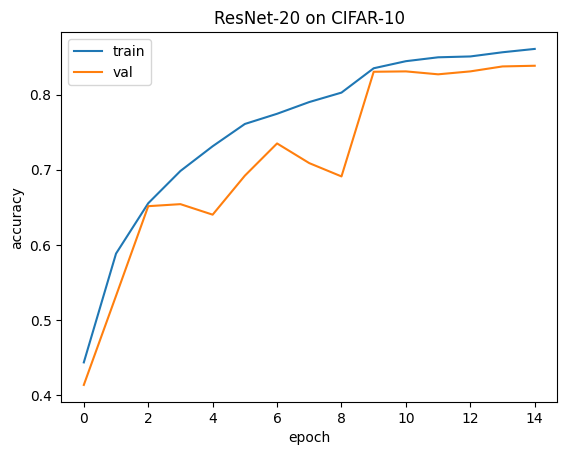

In [8]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.4f}")
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title(f"ResNet-{depth} on CIFAR-10"); plt.show()